Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


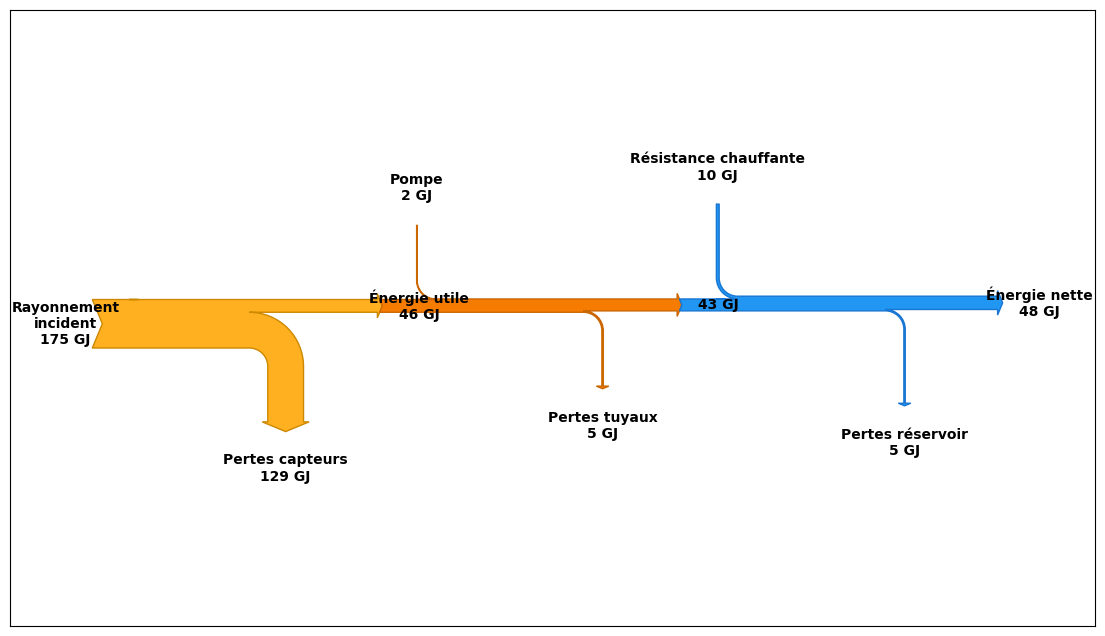

In [1]:
import matplotlib.pyplot as plt
from matplotlib.sankey import Sankey

# 1. Configuration de la figure
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(1, 1, 1, xticks=[], yticks=[])
#ax.set_title("Bilan Énergétique du Système (en GJ)", fontsize=16, fontweight='bold')

# 2. Initialisation de l'objet Sankey
sankey = Sankey(ax=ax, scale=0.0015, offset=0.2, head_angle=135, format='%.0f GJ', margin=0.3)

# 3. Construction des flux
# --- Nœud 1 (Couleur Jaune/Or) : Les Capteurs Solaires ---
sankey.add(flows=[175, -129, -46],
           labels=['Rayonnement\nincident', 'Pertes capteurs', 'Énergie utile'],
           orientations=[0, -1, 0],
           pathlengths=[0.2, 0.4, 0.4],
           facecolor='#FFB020',
           edgecolor='#cc8800')

# --- Nœud 2 (Couleur Orange/Rougeâtre) : La Tuyauterie ---
sankey.add(flows=[46, 2, -5, -43],
           labels=['', 'Pompe', 'Pertes tuyaux', ''],
           orientations=[0, 1, -1, 0],
           pathlengths=[0.2, 0.4, 0.4, 0.4],
           prior=0, connect=(2, 0),
           facecolor='#F57C00',
           edgecolor='#cc6600')

# --- Nœud 3 (Couleur Bleue) : Le Réservoir ---
sankey.add(flows=[43, 10, -5, -48],
           labels=['', 'Résistance chauffante', 'Pertes réservoir', 'Énergie nette'],
           orientations=[0, 1, -1, 0],
           pathlengths=[0.2, 0.5, 0.5, 0.5],
           prior=1, connect=(3, 0),
           facecolor='#2196F3',
           edgecolor='#1976D2')

# 4. Finalisation et génération des objets graphiques
diagrams = sankey.finish()

# 5. Rectifications des textes : garder la valeur de gauche
# Pour la transition 1 -> 2 (Jaune vers Orange), on garde le -262 GJ (sortie du Nœud 1) et on efface le 262 GJ (entrée du Nœud 2)
diagrams[1].texts[0].set_text('')
# Pour la transition 2 -> 3 (Orange vers Bleu), on garde le -244 GJ (sortie du Nœud 2) et on efface le 244 GJ (entrée du Nœud 3)
diagrams[2].texts[0].set_text('')

# Ajustement esthétique de la taille de tous les textes restants
for d in diagrams:
    for text in d.texts:
        text.set_fontsize(10)
        text.set_fontweight('bold')

# 6. Ajout des flèches d'annotation
# Flèche 1 : ajustée pour pointer vers le haut de la flèche orange
"""ax.annotate("Stockage d'énergie dans\nles tuyaux et l'échangeur",
            xy=(2.6, 0.55), xycoords='data',
            xytext=(2.6, 0.8), textcoords='data',
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
            fontsize=10, fontweight='bold', ha='center', color='#333333')

# Flèche 2 : ajustée pour pointer vers le bas de la flèche bleue
ax.annotate("Stockage d'énergie\ndans le réservoir",
            xy=(4, 0.2), xycoords='data',
            xytext=(4, -0.2), textcoords='data',
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
            fontsize=10, fontweight='bold', ha='center', color='#333333')"""

# Affichage
plt.show()

In [5]:
import plotly.graph_objects as go

# Nœuds : (étiquette, couleur, x, y) — x, y entre 0 et 1 (y = 0 en haut)
nodes = [
    ("Rayonnement PV<br>846 GJ",           "#7CB342", 0.001, 0.33),  # 0
    ("Pertes panneaux PV<br>717 GJ",       "#BDBDBD", 0.25,  0.28),  # 1
    ("Batterie + onduleur<br>129 GJ",      "#43A047", 0.25,  0.66),  # 2
    ("Énergie rejetée (dumped)<br>92 GJ",  "#BDBDBD", 0.50,  0.55),  # 3
    ("Pertes batterie/onduleur<br>9 GJ",   "#BDBDBD", 0.50,  0.68),  # 4
    ("Charge électrique<br>28 GJ",         "#2E7D32", 0.50,  0.76),  # 5
    ("Autres charges élec.<br>16 GJ",      "#81C784", 0.75,  0.73),  # 6
    ("Rayonnement capteurs<br>175 GJ",     "#FFB020", 0.001, 0.86),  # 7
    ("Pertes capteurs<br>129 GJ",          "#BDBDBD", 0.25,  0.84),  # 8
    ("Tuyauterie<br>48 GJ",                "#F57C00", 0.75,  0.88),  # 9
    ("Pertes tuyaux<br>5 GJ",              "#BDBDBD", 0.87,  0.82),  # 10
    ("Réservoir<br>53 GJ",                 "#2196F3", 0.87,  0.93),  # 11
    ("Pertes réservoir<br>5 GJ",           "#BDBDBD", 0.999, 0.86),  # 12
    ("Énergie nette<br>48 GJ",             "#1565C0", 0.999, 0.97),  # 13
    ("Pompe<br>2 GJ",                      "#2E7D32", 0.62,  0.84),  # 14
    ("Résistance chauffante<br>10 GJ",     "#2E7D32", 0.62,  0.95),  # 15
    ("Énergie utile<br>46 GJ",             "#FFB020", 0.50,  0.92),  # 16
]

VERT = "rgba(46,125,50,0.6)"
GRIS = "rgba(189,189,189,0.5)"

# (source, cible, valeur, couleur)
links = [
    (0, 1, 717, GRIS),
    (0, 2, 129, "rgba(67,160,71,0.5)"),
    (2, 3, 92,  GRIS),
    (2, 4, 9,   GRIS),
    (2, 5, 28,  VERT),
    (5, 6, 16,  "rgba(129,199,132,0.5)"),
    (5, 14, 2,  VERT),   # charge -> pompe
    (14, 9, 2,  VERT),   # pompe -> tuyauterie
    (5, 15, 10, VERT),   # charge -> résistance
    (15, 11, 10, VERT),  # résistance -> réservoir
    (7, 8, 129, GRIS),
    (7, 16, 46, "rgba(255,176,32,0.5)"),  # capteurs -> énergie utile
    (16, 9, 46, "rgba(255,176,32,0.5)"),  # énergie utile -> tuyauterie
    (9, 10, 5,  GRIS),
    (9, 11, 43, "rgba(245,124,0,0.5)"),
    (11, 12, 5, GRIS),
    (11, 13, 48, "rgba(33,150,243,0.5)"),
]

fig = go.Figure(go.Sankey(
    arrangement="snap",
    valueformat=".0f",
    valuesuffix=" GJ",
    node=dict(label=[n[0] for n in nodes], color=[n[1] for n in nodes],
              x=[n[2] for n in nodes], y=[n[3] for n in nodes],
              pad=15, thickness=18, line=dict(color="black", width=0.5)),
    link=dict(source=[l[0] for l in links], target=[l[1] for l in links],
              value=[l[2] for l in links], color=[l[3] for l in links]),
))

fig.update_layout(font=dict(size=12), width=1300, height=700,
                  margin=dict(l=20, r=20, t=20, b=50),
                  annotations=[dict(text="P<sub>grid</sub> = 0 GJ (fraction solaire électrique = 100 %)",
                                    x=0, y=-0.06, xref="paper", yref="paper",
                                    showarrow=False, font=dict(size=11))])

fig.show()
# fig.write_image("sankey_complet.png", scale=3)